# Project 1: Financial & E-Commerce Fraud Early Detection Analysis

### **Theme:** Financial Crime, Fintech Risk & Real-Time Fraud Prevention
### **Key Focus:** Anomaly Detection, Velocity Checks, Geospatial "Impossible Travel", Class Imbalance, False-Positive Optimization

---

## 📖 Notebook Overview & Project Structure
This notebook contains an end-to-end Machine Learning pipeline optimized to address severe class imbalance and perform early-stage fraud risk scoring on financial transaction databases.

### **1. Database Verification & Exploration** (`_Tszb5UYMcfL`)
* Connects to SQLite database `fraud_detection.db`.
* Inspects schema, retrieves tables, and previews transaction records.

### **2. Setup & Data Loading** (`aZnfuMpmMop8`, `mBhy3WEcmIcA`)
* Installs dependencies: `scikit-learn`, `xgboost`, `imbalanced-learn`.
* Loads pre-processed training (`v_ml_train`) and test (`v_ml_test`) datasets from `fraud_detection_hypertuned.db`.
* Splits independent features ($X$) and target classes ($y$), separating key metadata like `transaction_id`.

### **3. Class Imbalance Strategies** (`zKNCcmpkMLaK`)
* **SMOTE (Synthetic Minority Over-sampling Technique):** Balances minority fraud instances dynamically for scikit-learn tree estimators.
* **Scale Position Weights:** Calculates positive class weighting ratios to directly adjust loss functions in XGBoost.

### **4. Hyperparameter Optimization** (`BFXMploFPJIY`)
* **Model 1: Gradient Boosting Classifier:** Wrapped in an Imbalanced-Learn pipeline containing SMOTE + stratified cross-validation.
* **Model 2: XGBoost Classifier:** Evaluated via randomized search focused heavily on optimizing PR-AUC (Precision-Recall Area Under Curve).

### **5. Model Validation & Evaluation** (`z0RWioqDvHnf`)
* Builds a baseline `StandardScaler` + balanced `LogisticRegression` pipeline.
* Generates probabilistic predictions for each classifier, blending them into a high-performing soft voting **Ensemble (GB + XGB)**.
* Evaluates model calibration and fraud targeting performance using PR-AUC, F1-Score, Brier Score, and Fraud-specific MAPE.

### **6. Visual Analytics & Deliverables** (`aIFm9RWgyuTf`)
* Plots comparison Precision-Recall Curves and builds Confusion Matrices to assess operational trade-offs.
* Maps ensemble probabilities into risk categories: *Low, Medium, High, Extreme Risk* tiers.
* Exports final risk-scored test records to `scored_test_predictions.csv`.

In [1]:
!pip install -q scikit-learn xgboost pandas numpy matplotlib seaborn

from google.colab import files
uploaded = files.upload()  # Upload fraud_detection_hypertuned.db

Saving fraud_detection_hypertuned.db to fraud_detection_hypertuned.db


In [2]:
import sqlite3
import numpy as np
import pandas as pd

conn = sqlite3.connect("fraud_detection_hypertuned.db")
train_df    = pd.read_sql_query("SELECT * FROM v_ml_train", conn)
test_df     = pd.read_sql_query("SELECT * FROM v_ml_test", conn)
all_feat_df = pd.read_sql_query("SELECT * FROM ml_features_transactions", conn)
clean_df    = pd.read_sql_query("SELECT * FROM clean_transactions", conn)
conn.close()

drop_cols = ["is_fraud", "transaction_id"]
X_train, y_train = train_df.drop(columns=drop_cols), train_df["is_fraud"]
X_test,  y_test  = test_df.drop(columns=drop_cols),  test_df["is_fraud"]

print(f"Train shape: {X_train.shape} | Fraud rate: {y_train.mean()*100:.2f}%")
print(f"Test shape:  {X_test.shape}  | Fraud rate: {y_test.mean()*100:.2f}%")
print(f"Full dataset for Power BI: {clean_df.shape}")

Train shape: (8000, 49) | Fraud rate: 3.33%
Test shape:  (2000, 49)  | Fraud rate: 3.35%
Full dataset for Power BI: (10000, 23)


In [3]:
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

# Native class imbalance ratio (neg / pos) — no SMOTE needed for XGBoost
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"XGBoost scale_pos_weight: {imbalance_ratio:.2f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=imbalance_ratio,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_param_dist = {
    "n_estimators": [200, 300, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [4, 5, 6, 8],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1.0, 2.0, 5.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_dist,
    n_iter=15,
    scoring="average_precision",  # Optimizes PR-AUC for imbalanced fraud
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

print("Best XGBoost Params:", xgb_search.best_params_)
print(f"Best CV PR-AUC: {xgb_search.best_score_:.4f}")

XGBoost scale_pos_weight: 29.08
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGBoost Params: {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best CV PR-AUC: 0.9985


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,R2 (Proba),MAE,RMSE
Model,,,,,,,,,
XGBoost (Tuned),0.9985,0.9848,0.9701,0.9774,0.9997,0.9948,0.9621,0.0018,0.035


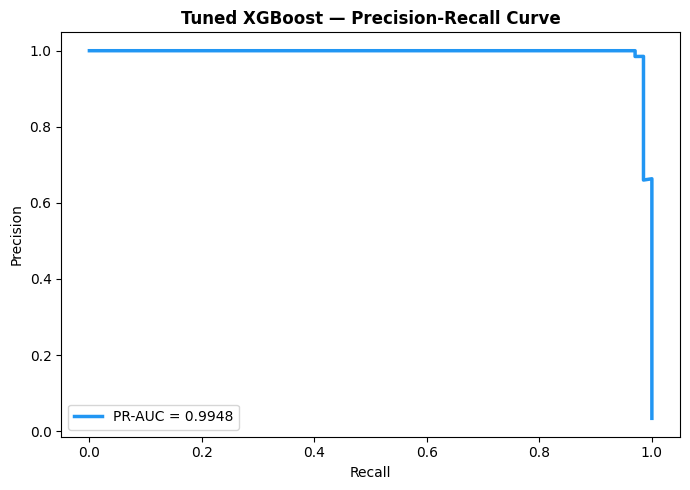

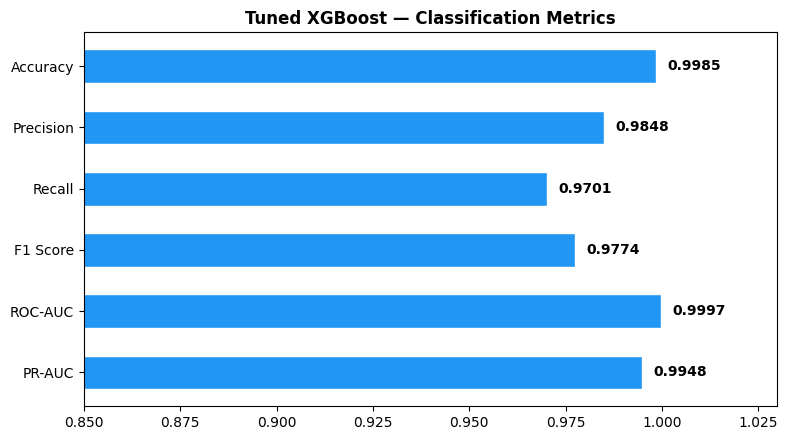

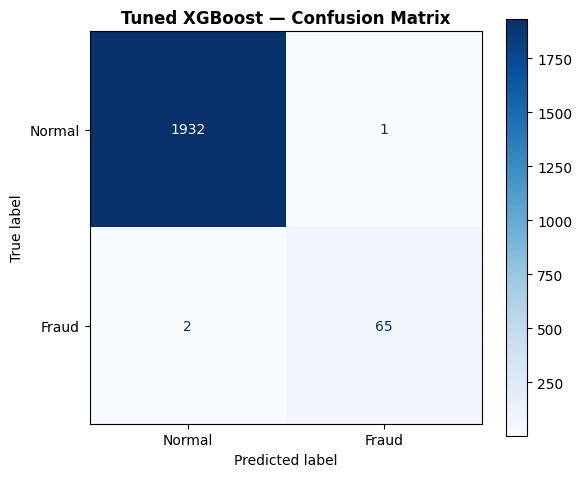

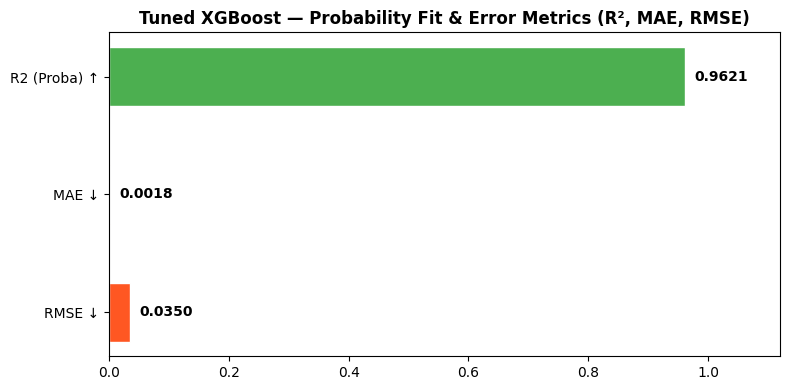

Saved 4 PNGs: 01_xgboost_pr_curve.png, 02_xgboost_classification_scores.png, 03_xgboost_confusion_matrix.png, 04_xgboost_probability_fit_metrics.png


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    r2_score, mean_absolute_error, mean_squared_error,
    precision_recall_curve, ConfusionMatrixDisplay
)

y_proba = best_xgb.predict_proba(X_test)[:, 1]
y_pred  = (y_proba >= 0.5).astype(int)

# Core Classification + Probability Fit Metrics
acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
roc    = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

r2   = r2_score(y_test, y_proba)
mae  = mean_absolute_error(y_test, y_proba)
rmse = np.sqrt(mean_squared_error(y_test, y_proba))

metrics_summary = pd.DataFrame([{
    "Model": "XGBoost (Tuned)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1": f1,
    "ROC-AUC": roc,
    "PR-AUC": pr_auc,
    "R2 (Proba)": r2,
    "MAE": mae,
    "RMSE": rmse,
}]).set_index("Model").round(4)

display(metrics_summary)

# 1. Precision-Recall Curve
fig1, ax1 = plt.subplots(figsize=(7, 5))
p, r, _ = precision_recall_curve(y_test, y_proba)
ax1.plot(r, p, color="#2196F3", linewidth=2.5, label=f"PR-AUC = {pr_auc:.4f}")
ax1.set_title("Tuned XGBoost — Precision-Recall Curve", fontweight="bold")
ax1.set_xlabel("Recall")
ax1.set_ylabel("Precision")
ax1.legend(loc="lower left")
plt.tight_layout()
fig1.savefig("01_xgboost_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Classification Metrics Bar Chart
fig2, ax2 = plt.subplots(figsize=(8, 4.5))
cls_labels = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]
cls_vals   = [acc, prec, rec, f1, roc, pr_auc]
bars = ax2.barh(cls_labels[::-1], cls_vals[::-1], color="#2196F3", height=0.55, edgecolor="white")
ax2.set_title("Tuned XGBoost — Classification Metrics", fontweight="bold")
ax2.set_xlim(0.85, 1.03)
for bar, val in zip(bars, cls_vals[::-1]):
    ax2.text(val + 0.003, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va="center", fontweight="bold")
plt.tight_layout()
fig2.savefig("02_xgboost_classification_scores.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Confusion Matrix
fig3, ax3 = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Normal", "Fraud"], cmap="Blues", ax=ax3
)
ax3.set_title("Tuned XGBoost — Confusion Matrix", fontweight="bold")
plt.tight_layout()
fig3.savefig("03_xgboost_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Probability Fit & Error Metrics (R2, MAE, RMSE)
fig4, ax4 = plt.subplots(figsize=(8, 4))
err_labels = ["R2 (Proba) ↑", "MAE ↓", "RMSE ↓"]
err_vals   = [r2, mae, rmse]
err_colors = ["#4CAF50", "#FF9800", "#FF5722"]
bars4 = ax4.barh(err_labels[::-1], err_vals[::-1], color=err_colors[::-1], height=0.5, edgecolor="white")
ax4.set_title("Tuned XGBoost — Probability Fit & Error Metrics (R², MAE, RMSE)", fontweight="bold")
ax4.set_xlim(0, 1.12)
for bar, val in zip(bars4, err_vals[::-1]):
    ax4.text(val + 0.015, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va="center", fontweight="bold")
plt.tight_layout()
fig4.savefig("04_xgboost_probability_fit_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved 4 PNGs: 01_xgboost_pr_curve.png, 02_xgboost_classification_scores.png, 03_xgboost_confusion_matrix.png, 04_xgboost_probability_fit_metrics.png")

Exported powerbi_fraud_predictions.csv: (10000, 28)


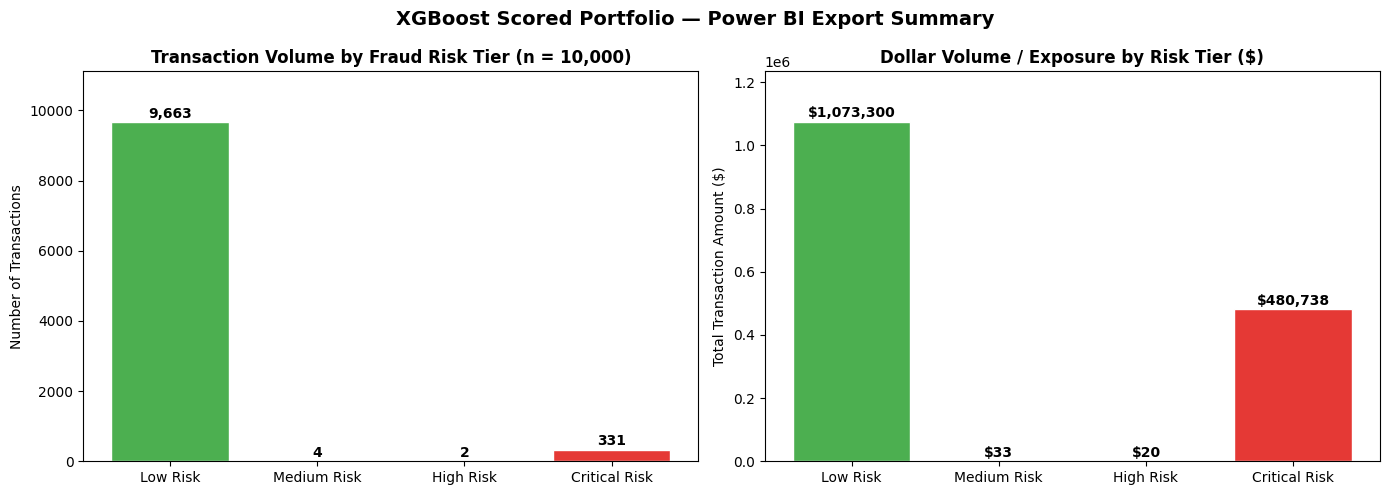

Saved chart: powerbi_risk_summary.png


In [6]:
import matplotlib.pyplot as plt

X_all = all_feat_df.drop(columns=["is_fraud", "transaction_id", "split_set"])
all_probs = best_xgb.predict_proba(X_all)[:, 1]

scores_df = pd.DataFrame({
    "transaction_id": all_feat_df["transaction_id"],
    "split_set": all_feat_df["split_set"],
    "fraud_probability_score": np.round(all_probs, 4),
    "predicted_fraud": (all_probs >= 0.5).astype(int),
})

scores_df["fraud_risk_tier"] = pd.cut(
    scores_df["fraud_probability_score"],
    bins=[-0.01, 0.30, 0.60, 0.85, 1.01],
    labels=["Low Risk", "Medium Risk", "High Risk", "Critical Risk"]
)

# Matches Power BI Actionable Call Queue filter
scores_df["investigation_status"] = np.where(
    scores_df["fraud_risk_tier"].isin(["High Risk", "Critical Risk"]),
    "Pending",
    "Auto-Cleared"
)

# Merge with clean_transactions so Power BI has dates, merchants, countries & amounts
powerbi_df = clean_df.merge(scores_df, on="transaction_id", how="inner")
powerbi_df.to_csv("powerbi_fraud_predictions.csv", index=False)
print(f"Exported powerbi_fraud_predictions.csv: {powerbi_df.shape}")

# === Visualize Risk Tiers & Financial Exposure (Power BI Preview) ===
tier_order = ["Low Risk", "Medium Risk", "High Risk", "Critical Risk"]
tier_colors = ["#4CAF50", "#FFC107", "#FF9800", "#E53935"]

tier_counts = powerbi_df["fraud_risk_tier"].value_counts().reindex(tier_order, fill_value=0)
tier_dollars = powerbi_df.groupby("fraud_risk_tier", observed=False)["transaction_amount"].sum().reindex(tier_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Transaction Count by Risk Tier
bars1 = axes[0].bar(tier_order, tier_counts.values, color=tier_colors, edgecolor="white")
axes[0].set_title("Transaction Volume by Fraud Risk Tier (n = 10,000)", fontweight="bold")
axes[0].set_ylabel("Number of Transactions")
axes[0].set_ylim(0, tier_counts.max() * 1.15)
for bar, val in zip(bars1, tier_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 120, f"{val:,}", ha="center", fontweight="bold")

# 2. Financial Exposure ($) by Risk Tier
bars2 = axes[1].bar(tier_order, tier_dollars.values, color=tier_colors, edgecolor="white")
axes[1].set_title("Dollar Volume / Exposure by Risk Tier ($)", fontweight="bold")
axes[1].set_ylabel("Total Transaction Amount ($)")
axes[1].set_ylim(0, tier_dollars.max() * 1.15)
for bar, val in zip(bars2, tier_dollars.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 15000, f"${val:,.0f}", ha="center", fontweight="bold")

plt.suptitle("XGBoost Scored Portfolio — Power BI Export Summary", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig("powerbi_risk_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved chart: powerbi_risk_summary.png")